# 이진 분류 실험 ① — 기본 피처만으로 선행 연구 방식 재현
1. 피처는 논문의 "기본 피처"만 (Multi-GNN `data_loading.py` 와 동일): 엣지 = Timestamp, Amount Received, Received Currency, Payment Format / 노드 = 전부 1
   GNN 에는 Multi-GNN 최고 설정대로 port numbering 2열(in_port, out_port)을 추가. 트리 모델은 기본 4개만 (GFP 논문의 "basic")
2. 불균형 처리는 가중 손실만 (Multi-GNN `w_ce = [1, 6.27]`, 트리는 `scale_pos_weight = 6`). 다운샘플링 없음
3. GNN 은 Multi-GNN 처럼 `to` / `rev_to` 두 간선 타입의 hetero 그래프 (역방향 MP), ego ID, `LinkNeighborLoader` 로 target 2048개가 서브그래프 공유, 이웃 2홉 × 방향별 100
4. 에폭은 FraudGT 처럼 "배치 256개" 로 고정. 400 에폭 = 학습 데이터 약 2바퀴. 검증은 4 에폭마다
5. 검증은 05 와 같은 가중 표본(양성 전부 + 정상 2%), **테스트는 구간 전체** (논문과 나란히 놓는 수치)
6. 이 노트북이 기준선. 다음 노트북부터 피처를 하나씩 추가하며 성능 변화를 본다 (GFP Table 5, BlazingAML Table 2 방식)

# 선행 연구 설정 요약
| | Multi-GNN (Egressy 2024) | FraudGT (Lin 2024) | 이 노트북 |
|---|---|---|---|
| 엣지 피처 | Timestamp, Amount Received, Received Currency, Payment Format + in/out port (z-norm) | 같음 | 같음 (6열) |
| 노드 피처 | 전부 1 (+ ego ID) | 같음 | 같음 |
| 역방향 MP | `to` / `rev_to` hetero, `to_hetero(aggr='mean')` | 같음 | 같음 (타입별 GINEConv 평균) |
| 이웃 샘플링 | 2홉 × 방향별 100 | 2홉 × 50 | 2홉 × 방향별 100 |
| 배치 | 8192 target | 2048 target | 2048 |
| 손실 | CE, 가중치 [1, 6.27] | CE, 가중치 [1, 6] | CE, 가중치 [1, 6.27] |
| 옵티마이저 | Adam lr 0.006 고정 | AdamW + cosine | Adam lr 0.006 고정 |
| 에폭 | 전체 1회 통과 | 배치 256개, 500 에폭, 검증 4 에폭마다 | 배치 256개, 400 에폭(약 2바퀴), 검증 4 에폭마다 |
| 에폭 선택 | 검증 F1 (argmax) | 검증 F1 | 검증 AP (05 와 통일) + F1@0.5 도 기록 |
| 분할 | 시간순 60/20/20 | 같음 | 주 단위 8/8~10/2 · ~10/16 · ~10/30 (05 와 동일) |
| 검증 / 테스트 | 전체 / 전체 | 학습 중 서브셋 / 마지막 전체 | 가중 표본 / 전체 |

# 공통 부분 (작업 준비, 데이터 준비)

## 0. 작업 준비

In [1]:
# pip install --break-system-packages --no-cache-dir pyg_lib -f https://data.pyg.org/whl/torch-2.10.0+cu126.html

In [2]:
# !pip install --break-system-packages --no-cache-dir -q lightgbm xgboost
# !pip install --break-system-packages --no-cache-dir -q duckdb pyarrow

In [3]:
import sys, json, time, random, gc
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm.auto import tqdm

In [4]:
# 05 샘플링 실험의 공통 모듈 (경로, 분할, 검증 표본, 지표) 를 그대로 쓴다
sys.path.append(str(Path.cwd().parent))
import sampling_lib as L

In [5]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DEVICE

device(type='cuda')

In [6]:
# ---- 실험 설정 ------------------------------------------------------------
DATASET = 'HI-Large'
SMOKE = False                 # True 면 학습 target·에폭을 줄여서 빨리 한 바퀴만 돈다

# 분할 — 데이터셋마다 기간이 달라서 따로 잡는다
#   HI-Large (97일): 05 실험과 동일, 월~일 주 단위, 11월 미사용
#   HI-Small (10일, 2022-09-01~09-10): 일 단위 60/20/20 (Multi-GNN 규칙)
WINDOWS = {
    'HI-Large': dict(train=L.TRAIN, val=L.VAL, test=L.TEST),
    'HI-Small': dict(train='2022-09-01:2022-09-06', val='2022-09-07:2022-09-08', test='2022-09-09:2022-09-10'),
}
TRAIN_WINDOW, VAL_WINDOW, TEST_WINDOW = (WINDOWS[DATASET][k] for k in ('train', 'val', 'test'))
VAL_NEG_RATE = 0.02           # 검증 표본: 양성 전부 + 정상 2% (가중치 1/rate). 05 와 같은 파일을 공유. 테스트는 전체

# 기본 피처 (Multi-GNN data_loading.py 의 edge_features 그대로) + port numbering (GNN 에만)
BASIC_EDGE_FEATURES = ['timestamp', 'amount_received', 'received_currency', 'payment_format']
PORT_FEATURES = ['in_port', 'out_port']

# 트리 모델 (기본 4개만)
SCALE_POS_WEIGHT = 6          # Altman 2023 / GFP 탐색 범위 1~10 의 중간
TREE_ROUNDS = 500
TREE_EARLY_STOP = 20

# GNN (Multi-GNN model_settings.json 'gin' 기준)
NUM_NEIGHBORS = [100, 100]    # 홉당 이웃 수. hetero 라 to / rev_to 각각 100 (Multi-GNN·v10 과 동일. FraudGT 는 50)
BATCH_SIZE = 2048             # target 간선 수 (FraudGT)
ITER_PER_EPOCH = 256          # 에폭 = 배치 256개 = 52만 target (FraudGT). 전체 1회 통과가 아님
EPOCHS = 400                  # 1바퀴 = 1.02억 / 52만 = 195 에폭 → 400 = 약 2바퀴 (FraudGT 500 = 2.6바퀴)
EVAL_PERIOD = 4               # 검증 주기(에폭). FraudGT eval_period 4. 검증마다 그래프 교체 2분이 들어 매 에폭은 안 한다
PATIENCE = 8                  # 검증 8회(32 에폭) 연속 개선 없을 때 멈춤. 검증 AP 가 ±0.03 흔들려서 넉넉히
CLASS_WEIGHT = [1.0, 6.27]    # Multi-GNN w_ce1, w_ce2
N_HIDDEN = 66
N_GNN_LAYERS = 2
LR = 0.006
DROPOUT = 0.01
FINAL_DROPOUT = 0.1
NUM_WORKERS = 0               # 샘플링 워커. Docker /dev/shm 이 64MB 라 워커가 공유 메모리를 못 써서 0

if SMOKE:
    ITER_PER_EPOCH, EPOCHS, TREE_ROUNDS, EVAL_PERIOD = 8, 2, 20, 1

OUT_DIR = Path.cwd() / 'results' / DATASET / 'basic_features'
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR

PosixPath('/workspace/money_laundry_ai_/code/binary_classification/results/HI-Large/basic_features')

In [7]:
# sampling_lib 은 DATASET 상수를 모듈 로드 시점에 읽으므로, Small 로 돌릴 땐 경로를 바꿔 준다
L.DATASET = DATASET
L.BASE = L.ROOT / 'parquets' / DATASET
L.SAMPLING = L.BASE / 'sampling'
TX_PATH = L.BASE / 'transactions.parquet'
assert TX_PATH.is_file(), f'01_prepare_parquet 을 {DATASET} 으로 먼저 실행: {TX_PATH}'
TX_PATH

PosixPath('/workspace/money_laundry_ai_/parquets/HI-Large/transactions.parquet')

## 1. 데이터 준비 — 거래 전체에서 기본 피처 4개 + port numbering

- `transactions.parquet` 에서 라벨과 기본 피처에 필요한 열만 읽는다 (중복 거래는 01 에서 대표 1건만 남긴 상태)
- 통화·결제 방식은 Multi-GNN 처럼 정수 코드로 (논문은 one-hot 이 아니라 코드값을 z-norm 한다. 그대로 따른다)
- 시각은 "데이터 시작부터 초" 로 (Multi-GNN `Timestamp - min`)
- z-norm 통계는 **학습 구간 거래**로만 구해서 검증·테스트에도 같은 값을 쓴다
- **port numbering** (Multi-GNN `ports()`): 계좌 v 가 받은 상대 계좌들을 **처음 거래 시각순**으로 0, 1, 2, … 번호 매긴 것.
  거래 u→v 의 `in_port` = v 의 받은 상대 중 u 의 번호, `out_port` = u 의 보낸 상대 중 v 의 번호. "같은 상대와 반복 거래인가, 새 상대인가" 를 모델이 알게 한다.
  번호는 첫 거래 시각으로 정해지므로 나중 거래가 들어와도 기존 번호는 안 바뀐다 → 전체 데이터로 한 번만 계산해도 구간별 그래프와 같은 값.
  Multi-GNN 처럼 두 열 모두 z-norm 하고, 역방향 간선에는 두 열을 바꿔 붙인다


In [8]:
con = L.connect(threads=8, memory='12GB')
train_a, train_b = L.parse_window(TRAIN_WINDOW)

# 통화·결제 방식 → 정수 코드. 학습 구간에서 본 값에 0,1,2,... 를 주고, 못 본 값은 -1 (문자열을 pandas 에 올리지 않는다)
currency_codes = con.execute(f"""
    SELECT receiving_currency AS v, row_number() OVER (ORDER BY receiving_currency) - 1 AS code
    FROM (SELECT DISTINCT receiving_currency FROM read_parquet({L.q(TX_PATH)})
          WHERE day BETWEEN DATE {L.q(train_a)} AND DATE {L.q(train_b)})""").df()
format_codes = con.execute(f"""
    SELECT payment_format AS v, row_number() OVER (ORDER BY payment_format) - 1 AS code
    FROM (SELECT DISTINCT payment_format FROM read_parquet({L.q(TX_PATH)})
          WHERE day BETWEEN DATE {L.q(train_a)} AND DATE {L.q(train_b)})""").df()
con.register('currency_codes', currency_codes); con.register('format_codes', format_codes)
currency_codes, format_codes

(                    v  code
 0   Australian Dollar     0
 1             Bitcoin     1
 2         Brazil Real     2
 3     Canadian Dollar     3
 4                Euro     4
 5        Mexican Peso     5
 6               Ruble     6
 7               Rupee     7
 8         Saudi Riyal     8
 9              Shekel     9
 10        Swiss Franc    10
 11           UK Pound    11
 12          US Dollar    12
 13                Yen    13
 14               Yuan    14,
               v  code
 0           ACH     0
 1       Bitcoin     1
 2          Cash     2
 3        Cheque     3
 4   Credit Card     4
 5  Reinvestment     5
 6          Wire     6)

In [9]:
# port numbering — numpy 정렬로 계산해 parquet 로 저장. 한 번 만들면 파일을 재사용한다
#   in_port : 계좌 v 가 받은 상대들을 첫 거래 시각순으로 0,1,2,... 매겼을 때 u 의 번호 (거래 u→v)
#   out_port: 계좌 u 가 보낸 상대들을 첫 거래 시각순으로 매겼을 때 v 의 번호
#   DuckDB 윈도 함수 + 조인 2번 + ORDER BY 는 1.8억 건에서 메모리 한도를 넘겨 커널이 죽었다 → numpy (최대 약 11GB, tx 로드 전이라 여유)
PORTS_PATH = L.BASE / 'features_ports' / 'ports.parquet'

def port_numbers(owner, other, t, n_nodes):
    """owner 계좌 안에서 상대(other)를 첫 거래 시각순으로 번호 매긴 값을 간선마다 돌려준다"""
    key = owner.astype(np.int64) * n_nodes + other                     # (owner, other) 쌍 → 정수 키
    order = np.lexsort((t, key))                                        # 키 순, 같은 키 안에선 시각 순
    key_s = key[order]
    first = np.empty(len(key_s), bool); first[0] = True; np.not_equal(key_s[1:], key_s[:-1], out=first[1:])
    pair_key = key_s[first]; pair_t = t[order][first]                   # 쌍마다 첫 거래 시각
    del order, key_s, first
    p_owner, p_other = pair_key // n_nodes, pair_key % n_nodes
    o2 = np.lexsort((p_other, pair_t, p_owner))                         # owner 안에서 (첫 시각, 상대) 순
    po = p_owner[o2]
    start = np.empty(len(po), bool); start[0] = True; np.not_equal(po[1:], po[:-1], out=start[1:])
    grp_start = np.maximum.accumulate(np.where(start, np.arange(len(po)), 0))
    rank = np.empty(len(po), np.int32); rank[o2] = (np.arange(len(po)) - grp_start).astype(np.int32)
    del o2, po, start, grp_start, p_owner, p_other, pair_t
    return rank[np.searchsorted(pair_key, key)]                         # 간선 → 쌍 번호

if not PORTS_PATH.exists():
    PORTS_PATH.parent.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    arr = con.execute(f"SELECT edge_id, src::INT AS src, dst::INT AS dst, epoch(ts)::BIGINT AS t FROM read_parquet({L.q(TX_PATH)}) ORDER BY edge_id").fetchnumpy()
    n_nodes = int(max(arr['src'].max(), arr['dst'].max())) + 1
    ports_df = pd.DataFrame(dict(edge_id=arr['edge_id'],
                                 in_port=port_numbers(arr['dst'], arr['src'], arr['t'], n_nodes),
                                 out_port=port_numbers(arr['src'], arr['dst'], arr['t'], n_nodes)))
    del arr; gc.collect()
    ports_df.to_parquet(PORTS_PATH, index=False)
    del ports_df; gc.collect()
    print(f'ports.parquet 생성 {time.time()-t0:.0f}s')
con.execute(f"SELECT count(*), max(in_port), max(out_port), avg(in_port), avg(out_port) FROM read_parquet({L.q(PORTS_PATH)})").df()

,count_star(),max(in_port),max(out_port),avg(in_port),avg(out_port)
0,179702079,2303,55955,1.690105,1249.299927


In [10]:
tx = con.execute(f"""
    SELECT t.edge_id, t.src::INT AS src, t.dst::INT AS dst, CAST(t.day AS TIMESTAMP) AS day,
           epoch(t.ts) - (SELECT epoch(min(ts)) FROM read_parquet({L.q(TX_PATH)}))  AS timestamp,   -- 데이터 시작부터 초
           t.received::FLOAT                        AS amount_received,
           coalesce(c.code, -1)::SMALLINT           AS received_currency,
           coalesce(f.code, -1)::SMALLINT           AS payment_format,
           t.is_laundering::TINYINT                 AS y
    FROM read_parquet({L.q(TX_PATH)}) t
    LEFT JOIN currency_codes c ON c.v = t.receiving_currency
    LEFT JOIN format_codes   f ON f.v = t.payment_format
    ORDER BY t.edge_id""").df()

# port 두 열은 parquet 에서 따로 읽어 붙인다 (DuckDB 에서 1.8억 × 1.8억 조인을 하면 메모리 초과). 둘 다 edge_id 순이라 행이 맞는지 확인하고 붙임
import pyarrow.parquet as pq
ports_tbl = pq.read_table(PORTS_PATH)
assert (ports_tbl.column('edge_id').to_numpy() == tx['edge_id'].to_numpy()).all(), 'ports.parquet 행 순서가 tx 와 다름'
tx['in_port'] = ports_tbl.column('in_port').to_numpy(); tx['out_port'] = ports_tbl.column('out_port').to_numpy()
del ports_tbl; gc.collect()
tx.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(179702079, 11)

In [11]:
tx.head()

,edge_id,src,dst,day,timestamp,amount_received,received_currency,payment_format,y,in_port,out_port
0,1,3,3,2022-08-01,0.0,19.180000,12,5,0,0,0
1,2,25,78803,2022-08-01,0.0,17955.109375,12,3,0,0,0
2,3,31,86028,2022-08-01,0.0,1199.829956,12,2,0,0,0
3,4,39,269980,2022-08-01,0.0,148565.453125,12,6,0,0,0
4,5,50,29866,2022-08-01,0.0,227247.421875,12,3,0,0,0


In [12]:
def window_mask(df, window):
    a, b = L.parse_window(window)
    return ((df['day'] >= pd.Timestamp(a)) & (df['day'] <= pd.Timestamp(b))).to_numpy()

in_train = window_mask(tx, TRAIN_WINDOW)

# z-norm: 학습 구간 통계로 전 구간 정규화 (Multi-GNN z_norm 과 같은 꼴). 트리는 앞 4열, GNN 은 6열 전부
# 메모리: tx[6열].to_numpy() 는 dtype 이 섞여 있어 float64 로 먼저 합친다(8.6GB) → 열 하나씩 float32 배열에 채운다.
#         뽑은 열은 tx 에서 떨어뜨려 비운다 (1.8억 행이라 열 하나가 0.7~1.4GB)
GNN_EDGE_FEATURES = BASIC_EDGE_FEATURES + PORT_FEATURES
feat_z = np.empty((len(tx), len(GNN_EDGE_FEATURES)), np.float32)
mu = np.empty(len(GNN_EDGE_FEATURES), np.float32); sd = np.empty(len(GNN_EDGE_FEATURES), np.float32)
for j, col in enumerate(GNN_EDGE_FEATURES):
    feat_z[:, j] = tx[col].to_numpy()
    mu[j] = feat_z[in_train, j].mean(); sd[j] = feat_z[in_train, j].std() + 1e-6
    feat_z[:, j] -= mu[j]; feat_z[:, j] /= sd[j]
tx.drop(columns=GNN_EDGE_FEATURES, inplace=True); gc.collect()
basic_z = feat_z[:, :len(BASIC_EDGE_FEATURES)]        # 트리용 뷰 (복사 아님)

pd.DataFrame({'feature': GNN_EDGE_FEATURES, 'mean(train)': mu, 'std(train)': sd})

,feature,mean(train),std(train)
0,timestamp,3.036519e+06,1.403026e+06
1,amount_received,5.573174e+06,1.804616e+09
2,received_currency,8.450158e+00,4.231340e+00
3,payment_format,2.946519e+00,1.430707e+00
4,in_port,1.691504e+00,2.026216e+01
5,out_port,1.258211e+03,5.523149e+03


In [13]:
# 라벨 분포 확인 (구간별)
for name, w in [('train', TRAIN_WINDOW), ('val', VAL_WINDOW), ('test', TEST_WINDOW)]:
    m = window_mask(tx, w)
    print(f'{name:5s} {w}  거래 {m.sum():>12,}  세탁 {tx.loc[m, "y"].sum():>8,}  비율 {tx.loc[m, "y"].mean()*100:.3f}%')

train 2022-08-08:2022-10-02  거래  102,336,629  세탁  110,671  비율 0.108%
val   2022-10-03:2022-10-16  거래   24,413,046  세탁   33,795  비율 0.138%
test  2022-10-17:2022-10-30  거래   26,808,230  세탁   34,460  비율 0.129%


## 2. 검증·테스트 표본 (05 실험과 공유)

- 검증: 구간 전체(2,440만 건)를 4 에폭마다 평가하면 한 번에 2시간이라 불가능 → **양성 전부 + 정상 2% (가중치 50)** 표본. 가중 지표는 전체의 불편추정이고 05 와 같은 파일
- 테스트: 마지막에 한 번이므로 **구간 전체** (2,680만 건, 가중치 1). 논문 수치와 나란히 놓는 값

In [14]:
def val_sample(con, window, rate, seed=0):
    """고정 검증 표본 (05_sampling_train.val_sample 과 같은 규칙·같은 파일). 없으면 만든다."""
    a, b = L.parse_window(window)
    path = L.SAMPLING / 'val' / f'{a}_{b}_neg{rate:g}.parquet'
    if path.exists():
        return pd.read_parquet(path)
    lab = L.load_labels(con, (a, b))
    rng = np.random.default_rng(seed)
    parts = [lab[lab.y == 1].assign(w=1.0)]
    for day, g in lab[lab.y == 0].groupby('day'):
        k = max(1, int(round(len(g) * rate)))
        parts.append(g.iloc[rng.choice(len(g), k, replace=False)].assign(w=len(g) / k))
    v = pd.concat(parts).sort_values('edge_id').reset_index(drop=True)
    path.parent.mkdir(parents=True, exist_ok=True)
    v.to_parquet(path, index=False)
    return v

val_df = val_sample(con, VAL_WINDOW, VAL_NEG_RATE)                       # 검증: 가중 표본 (05 공유)
test_df = L.load_labels(con, L.parse_window(TEST_WINDOW))[['edge_id', 'y', 'in_pattern']].assign(w=1.0)  # 테스트: 구간 전체, 가중치 1 (날짜 열은 2,680만 개 파이썬 객체라 뺌)
con.close()

val_df.shape, test_df.shape, int(test_df.y.sum())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

((521382, 7), (26808230, 4), 34460)

In [15]:
val_df.head()

,edge_id,day,src,dst,y,in_pattern,w
0,117269768,2022-10-03,11210,1050074,0,False,49.999844
1,117269781,2022-10-03,14672,1345482,0,False,49.999844
2,117269788,2022-10-03,15785,89179,0,False,49.999844
3,117269866,2022-10-03,41306,1339225,0,False,49.999844
4,117269893,2022-10-03,47308,410704,0,False,49.999844


In [16]:
# 표본의 edge_id → tx 행 위치 (tx 는 edge_id 오름차순이라 searchsorted 로 바로 찾는다)
all_edge_ids = tx['edge_id'].to_numpy()

def rows_of(edge_ids):
    pos = np.searchsorted(all_edge_ids, edge_ids)
    assert (all_edge_ids[pos] == edge_ids).all(), 'tx 에 없는 edge_id'
    return pos

val_idx  = rows_of(val_df['edge_id'].to_numpy())
test_idx = rows_of(test_df['edge_id'].to_numpy())
assert (tx['y'].to_numpy()[val_idx] == val_df['y'].to_numpy()).all()
del all_edge_ids
len(val_idx), len(test_idx)

(521382, 26808230)

In [17]:
def evaluate_sample(sample_df, score):
    """05 와 같은 가중 지표 + 논문 비교용 F1@0.5 (임계값 0.5 고정, 가중)."""
    y = sample_df['y'].to_numpy(); w = sample_df['w'].to_numpy()
    unmatched = (y == 1) & ~sample_df['in_pattern'].to_numpy()
    m = L.evaluate(y, score, w, unmatched)
    pred = score >= 0.5
    tp = (w * (pred & (y == 1))).sum(); fp = (w * (pred & (y == 0))).sum(); fn = (w * (~pred & (y == 1))).sum()
    m['F1_at_0.5'] = float(2 * tp / max(2 * tp + fp + fn, 1e-12))
    return m

results = {}   # 모델 이름 → {'val': 지표, 'test': 지표, ...}

# 트리 모델 기준선 (LightGBM, XGBoost)

## 3. 기본 피처 4개로 트리 모델

- 입력은 기본 피처 4개뿐 (계좌 ID 없음). GFP 논문 Table 4 의 "LightGBM basic / XGBoost basic" 에 해당 (HI-Large 24.5 / 10.6)
- 불균형은 `scale_pos_weight` 만. 검증 표본의 가중 AP 로 early stopping

In [18]:
train_mask = in_train
X_train = basic_z[train_mask]
y_train = tx['y'].to_numpy()[train_mask]
X_val, y_val, w_val = basic_z[val_idx], val_df['y'].to_numpy(), val_df['w'].to_numpy()
X_test = basic_z[test_idx]                      # 테스트 전체 2,680만 × 4

if SMOKE:
    keep = np.random.default_rng(SEED).choice(len(X_train), min(len(X_train), 200_000), replace=False)
    X_train, y_train = X_train[keep], y_train[keep]

X_train.shape, X_test.shape, y_train.mean()

((102336629, 4), (26808230, 4), np.float64(0.0010814407420045075))

In [19]:
import lightgbm as lgb

t0 = time.time()
lgb_model = lgb.LGBMClassifier(
    n_estimators=TREE_ROUNDS, learning_rate=0.05, num_leaves=63,
    scale_pos_weight=SCALE_POS_WEIGHT, subsample=0.8, subsample_freq=1, colsample_bytree=1.0,
    random_state=SEED, n_jobs=8, verbose=-1,
)
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)], eval_sample_weight=[w_val], eval_metric='average_precision',
    callbacks=[lgb.early_stopping(TREE_EARLY_STOP, verbose=False)],
)
lgb_sec = time.time() - t0

results['lightgbm_basic'] = dict(
    val=evaluate_sample(val_df, lgb_model.predict_proba(X_val)[:, 1]),
    test=evaluate_sample(test_df, lgb_model.predict_proba(X_test)[:, 1]),
    best_iteration=int(lgb_model.best_iteration_ or TREE_ROUNDS), train_sec=round(lgb_sec),
)
results['lightgbm_basic']['val']

/usr/local/lib/python3.12/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


{'AP': 0.04856105361477673,
 'F1': 0.12304120668481723,
 'precision': 0.07818617682724542,
 'recall': 0.28862257730433494,
 'threshold': 0.9987238390630798,
 'recall_at_1pct': 0.43885190116881195,
 'unmatched_recall_at_1pct': 0.06958744067177802,
 'ECE': 0.009391759651106666,
 'F1_at_0.5': 0.11312832534356926}

In [20]:
import xgboost as xgb

t0 = time.time()
xgb_model = xgb.XGBClassifier(
    n_estimators=TREE_ROUNDS, learning_rate=0.05, max_depth=8,
    scale_pos_weight=SCALE_POS_WEIGHT, subsample=0.8, colsample_bytree=1.0,
    tree_method='hist', device='cpu',          # 최신 xgboost GPU 커널이 V100(sm_70) 을 지원하지 않아 CPU 로
    eval_metric='aucpr', early_stopping_rounds=TREE_EARLY_STOP,
    random_state=SEED, n_jobs=8,
)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], sample_weight_eval_set=[w_val], verbose=False)
xgb_sec = time.time() - t0

results['xgboost_basic'] = dict(
    val=evaluate_sample(val_df, xgb_model.predict_proba(X_val)[:, 1]),
    test=evaluate_sample(test_df, xgb_model.predict_proba(X_test)[:, 1]),
    best_iteration=int(xgb_model.best_iteration), train_sec=round(xgb_sec),
)
results['xgboost_basic']['val']

{'AP': 0.05614451415704122,
 'F1': 0.13011548473756204,
 'precision': 0.09053025415320519,
 'recall': 0.23121763574493268,
 'threshold': 0.45901623368263245,
 'recall_at_1pct': 0.4434975588104749,
 'unmatched_recall_at_1pct': 0.06381891201168309,
 'ECE': 0.009510450346360003,
 'F1_at_0.5': 0.1272345578050196}

In [21]:
# 피처 중요도 — 기본 피처 4개 중 뭘 보는지
xgb_gain = xgb_model.get_booster().get_score(importance_type='gain')
pd.DataFrame({
    'feature': BASIC_EDGE_FEATURES,
    'lightgbm_gain': lgb_model.booster_.feature_importance('gain'),
    'xgboost_gain': [xgb_gain.get(f'f{i}', 0.0) for i in range(len(BASIC_EDGE_FEATURES))],
})

,feature,lightgbm_gain,xgboost_gain
0,timestamp,3.030422e+06,98.148163
1,amount_received,2.553631e+07,584.453247
2,received_currency,1.793376e+07,515.631104
3,payment_format,1.552910e+07,15143.089844


In [22]:
# 그래프를 만들기 전에 트리 학습용 배열을 지운다 (X_train 1.6GB + X_test 0.4GB + 트리 내부 데이터 수 GB). 모델 객체는 가볍게 남는다
import gc
del X_train, y_train, X_test
gc.collect()

111

# GNN (Multi-GNN 구조, FraudGT 식 학습)

## 4. 그래프 만들기

- 그래프는 Multi-GNN 규칙: 학습 그래프 = 학습 구간 **끝까지**의 거래 (8/7 이전 포함), 검증 그래프 = 검증 구간 끝까지, 테스트 그래프 = 테스트 구간 끝까지
- Multi-GNN 과 같은 **hetero 그래프**: 간선 타입 `('node','to','node')` = 거래 u→v, `('node','rev_to','node')` = 뒤집은 v→u (역방향 MP).
  이웃 샘플링이 타입별로 100개씩이라 "방향별 100" 이 된다. 엣지 피처는 두 타입 다 6열, rev_to 는 in_port/out_port 를 바꿔 붙임. 라벨·target 은 `to` 에만
- 노드 피처는 전부 1. ego ID(판정 대상 간선의 양끝 = 1) 는 배치 단위로 붙인다 (Multi-GNN `AddEgoIds`)
- **메모리** (HI-Large, 서버 한도 약 25GB): 세 번 터진 뒤 정리한 규칙
  - 샘플러는 간선을 도착 노드순으로 정렬한 사본을 타입마다 만든다 → 그래프를 만들 때 **미리 정렬**해 두고 `is_sorted=True` (사본 없음)
  - 엣지 피처 float16, 라벨 uint8 로 저장하고 배치에서만 float32 / long
  - **그래프는 한 번에 하나만** (`use_graph`): 학습 중엔 학습 그래프만, 검증할 때 바꿔 끼우고 다시 돌아온다 (각 1분). 테스트 그래프는 학습이 다 끝난 뒤
  - 큰 객체(tx, feat_z, 트리 배열)는 쓰고 나면 바로 지우고 `malloc_trim` 으로 OS 에 돌려준다

In [23]:
from torch_geometric.data import HeteroData
from torch_geometric.loader import LinkNeighborLoader
import ctypes, gc, psutil

TO, REV = ('node', 'to', 'node'), ('node', 'rev_to', 'node')

def trim():
    """지운 메모리를 OS 에 돌려주고(glibc 는 안 돌려줄 때가 많다) 현재 RSS 를 찍는다"""
    gc.collect(); ctypes.CDLL('libc.so.6').malloc_trim(0)
    print(f'RSS {psutil.Process().memory_info().rss / 1e9:.1f} GB')

NUM_NODES = int(max(tx['src'].max(), tx['dst'].max())) + 1

# 구간 끝 = tx 행 번호 (tx 는 시간순이라 "끝 날짜까지" = 앞부분)
def rows_until(window):
    _, end = L.parse_window(window)
    return int((tx['day'] <= pd.Timestamp(end)).sum())

N_TRAIN, N_VAL, N_TEST = rows_until(TRAIN_WINDOW), rows_until(VAL_WINDOW), rows_until(TEST_WINDOW)
print(f'간선 수 (정방향): 학습까지 {N_TRAIN:,}  검증까지 {N_VAL:,}  테스트까지 {N_TEST:,}')

# 그래프 재료만 남기고 tx, feat_z 는 지운다 (각각 7GB, 4.3GB)
SRC = tx['src'].to_numpy().copy(); DST = tx['dst'].to_numpy().copy(); Y = tx['y'].to_numpy().astype(np.uint8)
FEAT16 = torch.as_tensor(feat_z).to(torch.float16)          # [N, 6] = basic 4 + in_port + out_port
PORT_COLS = [len(BASIC_EDGE_FEATURES), len(BASIC_EDGE_FEATURES) + 1]   # in_port, out_port 열 번호 (rev_to 에서 교환)
del tx, feat_z, basic_z
trim()

간선 수 (정방향): 학습까지 117,269,636  검증까지 141,682,682  테스트까지 168,490,912
RSS 7.4 GB


In [24]:
def build_graph(n_rows, tx_rows):
    """tx 앞 n_rows 건으로 hetero 그래프 + target(tx_rows) 의 to 간선 위치.
    타입마다 간선을 도착 노드(col)순으로 정렬해 저장한다 (샘플러 is_sorted=True 용).
    메모리: 텐서를 미리 할당하고 제자리에서 채워 torch.stack / 이중 인덱싱 임시 복사본을 안 만든다 (검증 그래프 기준 순간 최대 약 20GB)"""
    t0 = time.time(); m = n_rows
    data = HeteroData(); data['node'].x = torch.ones(NUM_NODES, 1); data['node'].num_nodes = NUM_NODES
    src = torch.as_tensor(SRC[:m]); dst = torch.as_tensor(DST[:m])           # int32 뷰 (복사 없음)
    # --- to: u → v, col = dst 순 정렬 ---
    perm = torch.argsort(dst.to(torch.long))
    ei = torch.empty(2, m, dtype=torch.long); ei[0] = src[perm]; ei[1] = dst[perm]
    attr = torch.empty(m, FEAT16.shape[1], dtype=torch.float16); torch.index_select(FEAT16, 0, perm, out=attr)
    data[TO].edge_index, data[TO].edge_attr, data[TO].y = ei, attr, torch.as_tensor(Y[:m])[perm]
    fwd_pos = torch.empty(m, dtype=torch.long); fwd_pos[perm] = torch.arange(m)        # tx 행 → 정렬 후 위치
    targets = fwd_pos[torch.as_tensor(np.asarray(tx_rows))]
    assert (data[TO].y[targets].numpy() == Y[np.asarray(tx_rows)]).all(), 'target 위치 오류'
    del perm, fwd_pos, ei, attr
    # --- rev_to: v → u, col = src 순 정렬. 엣지 피처는 port 두 열을 바꿔서 ---
    perm = torch.argsort(src.to(torch.long))
    ei = torch.empty(2, m, dtype=torch.long); ei[0] = dst[perm]; ei[1] = src[perm]
    attr = torch.empty(m, FEAT16.shape[1], dtype=torch.float16); torch.index_select(FEAT16, 0, perm, out=attr)
    attr[:, PORT_COLS] = attr[:, PORT_COLS[::-1]]                                    # in_port ↔ out_port
    data[REV].edge_index, data[REV].edge_attr = ei, attr
    del perm, ei, attr, src, dst
    print(f'그래프 to {m:,} + rev_to {m:,} 간선 (정렬됨)  {time.time()-t0:.0f}s'); return data, targets

In [25]:
class AddEgoIdsAndTargetAttr:
    """배치 변환 3가지
    1) ego ID: 판정 대상(seed) 간선의 양끝 노드에 1, 나머지 0 인 피처 열을 x 에 붙인다 (Multi-GNN AddEgoIds)
    2) seed 간선의 원 엣지 피처를 batch.target_attr 로 싣는다 — 이웃 샘플링 결과에 seed 간선 자체가 빠질 수 있어서
       그래프 edge_attr 에서 직접 꺼낸다 (input_id = targets 안에서의 위치)
    3) 저장용 float16 / uint8 → 계산용 float32 / long"""
    def __init__(self, graph, targets):
        self.edge_attr, self.targets = graph[TO].edge_attr, targets
    def __call__(self, batch):
        ego = torch.zeros(batch['node'].num_nodes, 1)
        ego[batch[TO].edge_label_index.flatten()] = 1
        batch['node'].x = torch.cat([batch['node'].x, ego], 1)
        batch[TO].edge_attr = batch[TO].edge_attr.float(); batch[REV].edge_attr = batch[REV].edge_attr.float()
        batch.target_attr = self.edge_attr[self.targets[batch[TO].input_id]].float()   # [B, 6]
        batch[TO].edge_label = batch[TO].edge_label.long()
        return batch

def make_loader(graph, targets, shuffle):
    return LinkNeighborLoader(
        graph, num_neighbors={TO: NUM_NEIGHBORS, REV: NUM_NEIGHBORS},          # 타입별 → 방향별 100
        edge_label_index=(TO, graph[TO].edge_index[:, targets]), edge_label=graph[TO].y[targets],
        batch_size=BATCH_SIZE, shuffle=shuffle, transform=AddEgoIdsAndTargetAttr(graph, targets),
        is_sorted=True,                       # 타입마다 도착 노드순으로 정렬해 뒀으므로 샘플러가 정렬 사본을 안 만든다
        num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0,
    )

In [26]:
# 그래프 바꿔 끼우기 — 메모리에 그래프를 하나만 둔다
TRAIN_ROWS = np.flatnonzero(train_mask)
GRAPH = dict(name=None, graph=None, targets=None, loader=None)

def use_graph(name):
    """name 그래프('train' | 'val' | 'test') 와 그 loader 를 메모리에 올린다. 이미 올라와 있으면 그대로."""
    if GRAPH['name'] == name:
        return GRAPH['loader']
    GRAPH.update(name=None, graph=None, targets=None, loader=None); trim()         # 이전 그래프를 먼저 지운다
    n_rows, tx_rows, shuffle = dict(train=(N_TRAIN, TRAIN_ROWS, True), val=(N_VAL, val_idx, False), test=(N_TEST, test_idx, False))[name]
    graph, targets = build_graph(n_rows, tx_rows)
    if name == 'train' and SMOKE:
        targets = targets[torch.randperm(len(targets))[:50_000]]
    loader = make_loader(graph, targets, shuffle=shuffle)
    GRAPH.update(name=name, graph=graph, targets=targets, loader=loader); trim()
    return loader

EDGE_DIM = FEAT16.shape[1]                    # 기본 4 + port 2
# 주의: loader 를 전역 변수에 따로 담아 두면 그래프가 안 지워진다. 항상 use_graph(...) 로 받아서 바로 쓴다

In [27]:
# 배치 하나 꺼내서 모양 확인 — 2048 target 이 서브그래프 하나를 공유한다
batch = next(iter(use_graph('train')))
batch

RSS 8.2 GB
그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  43s
RSS 19.1 GB


HeteroData(
  target_attr=[2048, 6],
  node={
    x=[180175, 2],
    num_nodes=180175,
    n_id=[180175],
    num_sampled_nodes=[3],
  },
  (node, to, node)={
    edge_index=[2, 1638641],
    edge_attr=[1638641, 6],
    y=[1638641],
    e_id=[1638641],
    num_sampled_edges=[2],
    input_id=[2048],
    edge_label_index=[2, 2048],
    edge_label=[2048],
  },
  (node, rev_to, node)={
    edge_index=[2, 1529228],
    edge_attr=[1529228, 6],
    e_id=[1529228],
    num_sampled_edges=[2],
  }
)

In [28]:
print('노드', batch['node'].num_nodes, ' to 간선', batch[TO].num_edges, ' rev_to 간선', batch[REV].num_edges,
      ' target', batch[TO].edge_label_index.shape[1], ' 양성', int(batch[TO].edge_label.sum()),
      ' x 열', batch['node'].x.shape[1], '(1 + ego)', ' target_attr', tuple(batch.target_attr.shape))

노드 180175  to 간선 1638641  rev_to 간선 1529228  target 2048  양성 1  x 열 2 (1 + ego)  target_attr (2048, 6)


## 5. GNN 모델 — Multi-GNN `GINe` 그대로

- `GINe` (Egressy 2024 `models.py`) 를 Multi-GNN 의 `to_hetero(aggr='mean')` 과 같은 꼴로 직접 구현:
  타입(`to`, `rev_to`)마다 엣지 임베딩·GINEConv 를 따로 두고 두 conv 출력을 **평균** → BatchNorm → residual. 노드 임베딩·MLP 는 공유
- `edge_updates=True` 가 논문의 **GIN+EU** (층마다 타입별 엣지 임베딩도 갱신). 둘 다 돌린다
- 엣지 피처 차원 = 기본 4 + port 2 = 6. 노드 = 1 + ego 1 = 2

In [29]:
from torch_geometric.nn import GINEConv, BatchNorm

class GINe(nn.Module):
    """Multi-GNN GINe + to_hetero(aggr='mean'). 간선 타입 to / rev_to 각각 GINEConv, 출력 평균"""
    def __init__(self, num_features, edge_dim, n_hidden=66, num_gnn_layers=2, n_classes=2,
                 edge_updates=False, dropout=0.0, final_dropout=0.5):
        super().__init__()
        self.n_hidden, self.num_gnn_layers, self.edge_updates, self.dropout = n_hidden, num_gnn_layers, edge_updates, dropout
        self.node_emb = nn.Linear(num_features, n_hidden)
        self.edge_emb = nn.ModuleDict({t: nn.Linear(edge_dim, n_hidden) for t in ('fwd', 'rev')})
        self.convs = nn.ModuleList(); self.emlps = nn.ModuleList(); self.batch_norms = nn.ModuleList()
        for _ in range(num_gnn_layers):
            self.convs.append(nn.ModuleDict({t: GINEConv(nn.Sequential(nn.Linear(n_hidden, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_hidden)),
                                                         edge_dim=n_hidden) for t in ('fwd', 'rev')}))
            if edge_updates:
                self.emlps.append(nn.ModuleDict({t: nn.Sequential(nn.Linear(3 * n_hidden, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_hidden))
                                                 for t in ('fwd', 'rev')}))
            self.batch_norms.append(BatchNorm(n_hidden))
        self.mlp = nn.Sequential(nn.Linear(n_hidden * 3, 50), nn.ReLU(), nn.Dropout(final_dropout),
                                 nn.Linear(50, 25), nn.ReLU(), nn.Dropout(final_dropout),
                                 nn.Linear(25, n_classes))

    def forward(self, x, ei, ea, target_index, target_attr):
        """ei, ea: {'fwd': edge_index, 'rev': edge_index}, {'fwd': edge_attr, 'rev': edge_attr}  (키 'to' 는 nn.Module.to 와 겹쳐 못 씀)
        target_index: 판정할 간선의 (src, dst) 노드 번호 [2, B], target_attr: 그 간선의 원 피처 [B, edge_dim]. 반환 [B, 2] 로짓"""
        x = self.node_emb(x)
        ea = {t: self.edge_emb[t](ea[t]) for t in ('fwd', 'rev')}
        target_emb = self.edge_emb['fwd'](target_attr)
        for i in range(self.num_gnn_layers):
            h = (self.convs[i]['fwd'](x, ei['fwd'], ea['fwd']) + self.convs[i]['rev'](x, ei['rev'], ea['rev'])) / 2   # aggr='mean'
            x = (x + F.relu(self.batch_norms[i](h))) / 2
            x = F.dropout(x, self.dropout, self.training)
            if self.edge_updates:
                for t in ('fwd', 'rev'):
                    s, d = ei[t]
                    ea[t] = ea[t] + self.emlps[i][t](torch.cat([x[s], x[d], ea[t]], -1)) / 2
        h = torch.cat([x[target_index[0]], x[target_index[1]]], 1).relu()
        return self.mlp(torch.cat([h, target_emb], 1))

In [30]:
def forward_batch(model, batch):
    batch = batch.to(DEVICE)
    logits = model(batch['node'].x,
                   {'fwd': batch[TO].edge_index, 'rev': batch[REV].edge_index},
                   {'fwd': batch[TO].edge_attr,  'rev': batch[REV].edge_attr},
                   batch[TO].edge_label_index, batch.target_attr)
    return logits, batch[TO].edge_label

# 모양 확인
model = GINe(num_features=2, edge_dim=EDGE_DIM, n_hidden=N_HIDDEN, num_gnn_layers=N_GNN_LAYERS,
             dropout=DROPOUT, final_dropout=FINAL_DROPOUT).to(DEVICE)
logits, labels = forward_batch(model, batch)
logits.shape, labels.shape

(torch.Size([2048, 2]), torch.Size([2048]))

## 6. 학습 — 가중 CE + FraudGT 식 에폭

- 손실: `CrossEntropyLoss(weight=[1, 6.27])`. 배치 안 양성은 자연 비율(약 0.1%)로 들어온다 → 양성 손실 비중 ≈ 0.7%
- 에폭 = `ITER_PER_EPOCH` 배치. 셔플된 iterator 를 에폭 경계에서 끊지 않고 이어 쓴다 (FraudGT `LoaderWrapper`)
- `EVAL_PERIOD` 에폭마다 검증 표본 평가 (학습 그래프 ↔ 검증 그래프 교체 포함), 검증 AP 최고 에폭을 저장. 논문 비교용으로 F1@0.5 도 기록
- 400 에폭 × (학습 2분 + 검증 4회당 5분) ≈ 모델당 15~20시간. GINe 먼저 돌리고 결과 보고 GINe+EU

In [31]:
class InfiniteLoader:
    """셔플된 loader 를 끝까지 다 읽으면 다시 섞어서 이어 준다 (FraudGT LoaderWrapper 의 train 동작)."""
    def __init__(self, loader):
        self.loader, self.it = loader, iter(loader)
    def next(self):
        try:
            return next(self.it)
        except StopIteration:
            self.it = iter(self.loader)
            return next(self.it)

@torch.no_grad()
def predict_loader(model, loader):
    """loader 순서대로 양성 확률. (shuffle=False 라 targets 순서와 같다)"""
    model.eval(); out = []
    for b in loader:
        logits, _ = forward_batch(model, b)
        out.append(F.softmax(logits, -1)[:, 1].cpu().numpy())
    return np.concatenate(out)

In [32]:
def train_gnn(name, edge_updates):
    torch.manual_seed(SEED)
    model = GINe(num_features=2, edge_dim=EDGE_DIM, n_hidden=N_HIDDEN, num_gnn_layers=N_GNN_LAYERS,
                 edge_updates=edge_updates, dropout=DROPOUT, final_dropout=FINAL_DROPOUT).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(CLASS_WEIGHT, device=DEVICE))
    history, best_ap, stale, stream = [], -np.inf, 0, None
    ckpt = OUT_DIR / f'{name}.pt'
    t_start = time.time()
    for epoch in range(1, EPOCHS + 1):
        if GRAPH['name'] != 'train' or stream is None:          # 검증 뒤엔 학습 그래프를 다시 올린다 (셔플도 새로)
            stream = InfiniteLoader(use_graph('train'))
        model.train(); losses = []; te = time.time()
        for _ in tqdm(range(ITER_PER_EPOCH), desc=f'{name} epoch {epoch}', leave=False):
            logits, labels = forward_batch(model, stream.next())
            loss = loss_fn(logits, labels)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            losses.append(loss.item())
        row = dict(epoch=epoch, train_loss=float(np.mean(losses)), epoch_sec=round(time.time() - te))
        if epoch % EVAL_PERIOD == 0 or epoch == EPOCHS:
            stream = None
            score = predict_loader(model, use_graph('val'))
            m = evaluate_sample(val_df, score); row.update(m)
            print(f"epoch {epoch:2d}  loss {row['train_loss']:.4f}  AP {m['AP']:.4f}  F1 {m['F1']:.4f}  F1@0.5 {m['F1_at_0.5']:.4f}  "
                  f"recall@1% {m['recall_at_1pct']:.4f}  ({time.time() - te:.0f}s)")
            if m['AP'] > best_ap:
                best_ap, stale = m['AP'], 0
                torch.save(model.state_dict(), ckpt)
            else:
                stale += 1
        else:
            print(f"epoch {epoch:2d}  loss {row['train_loss']:.4f}  ({row['epoch_sec']}s)")
        history.append(row)
        if stale >= PATIENCE:
            break
    # 최고 검증 에폭 모델로 검증 지표 (테스트는 7절에서)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    hist = pd.DataFrame(history); hist.to_csv(OUT_DIR / f'{name}_history.csv', index=False)
    best = hist.loc[hist['AP'].idxmax()]
    results[name] = dict(
        val={k: float(best[k]) for k in ('AP', 'F1', 'F1_at_0.5', 'precision', 'recall', 'threshold', 'recall_at_1pct', 'unmatched_recall_at_1pct', 'ECE')},
        test=None,
        best_epoch=int(best['epoch']), epochs_run=len(hist), train_sec=round(time.time() - t_start),
        targets_seen=int(best['epoch']) * ITER_PER_EPOCH * BATCH_SIZE,
        gpu_peak_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE.type == 'cuda' else None,
    )
    return model, hist

In [33]:
gine_model, gine_hist = train_gnn('gine_basic', edge_updates=False)
results['gine_basic']['val']

gine_basic epoch 1:   0%|          | 0/256 [00:00<?, ?it/s]

epoch  1  loss 0.0367  (269s)


gine_basic epoch 2:   0%|          | 0/256 [00:00<?, ?it/s]

epoch  2  loss 0.0241  (233s)


gine_basic epoch 3:   0%|          | 0/256 [00:00<?, ?it/s]

...

gine_basic epoch 139:   0%|          | 0/256 [00:00<?, ?it/s]

epoch 139  loss 0.0164  (196s)


gine_basic epoch 140:   0%|          | 0/256 [00:00<?, ?it/s]

RSS 8.8 GB
그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  47s
RSS 16.9 GB
epoch 140  loss 0.0166  AP 0.4438  F1 0.5096  F1@0.5 0.5041  recall@1% 0.7497  (433s)


{'AP': 0.4614431630703218,
 'F1': 0.5182045760002252,
 'F1_at_0.5': 0.4842406161633057,
 'precision': 0.714168079444185,
 'recall': 0.40662819943778666,
 'threshold': 0.8045654892921448,
 'recall_at_1pct': 0.744666370764906,
 'unmatched_recall_at_1pct': 0.42650602409638555,
 'ECE': 0.0030246254765390417}

In [34]:
gine_eu_model, gine_eu_hist = train_gnn('gine_eu_basic', edge_updates=True)
results['gine_eu_basic']['val']

RSS 8.8 GB
그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  41s
RSS 19.7 GB


gine_eu_basic epoch 1:   0%|          | 0/256 [00:00<?, ?it/s]

epoch  1  loss 0.0312  (265s)


gine_eu_basic epoch 2:   0%|          | 0/256 [00:00<?, ?it/s]

epoch  2  loss 0.0240  (256s)


...

gine_eu_basic epoch 107:   0%|          | 0/256 [00:01<?, ?it/s]

epoch 107  loss 0.0156  (252s)


gine_eu_basic epoch 108:   0%|          | 0/256 [00:00<?, ?it/s]

RSS 8.8 GB
그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  48s
RSS 17.0 GB
epoch 108  loss 0.0168  AP 0.3504  F1 0.4094  F1@0.5 0.3166  recall@1% 0.7196  (531s)


{'AP': 0.41447220527976225,
 'F1': 0.45503918697100354,
 'F1_at_0.5': 0.4528574470352153,
 'precision': 0.5978440850703257,
 'recall': 0.36730285545198993,
 'threshold': 0.573544979095459,
 'recall_at_1pct': 0.7208462790353602,
 'unmatched_recall_at_1pct': 0.3859802847754655,
 'ECE': 0.0019817985470094676}

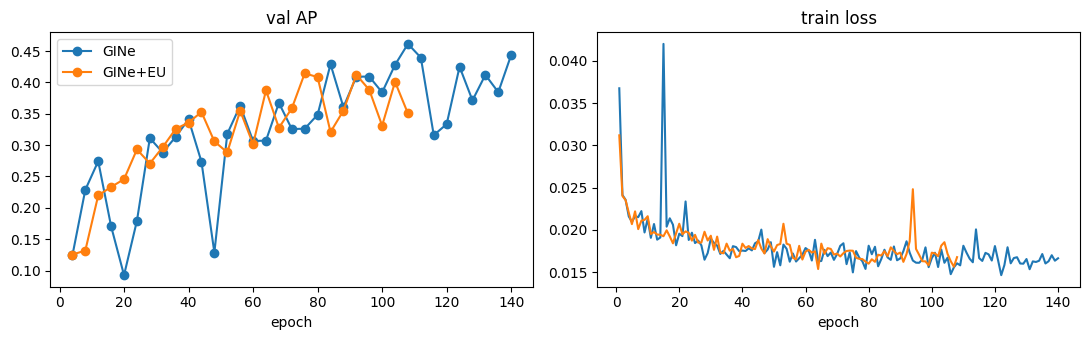

In [35]:
# 학습 곡선 — 에폭 = 52만 target 이므로 x 축은 "본 target 수" 로도 읽을 수 있다. 돌린 모델만 그린다
curves = [(n, h) for n, h in [('GINe', globals().get('gine_hist')), ('GINe+EU', globals().get('gine_eu_hist'))] if h is not None]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for name, h in curves:
    hv = h.dropna(subset=['AP']); ax[0].plot(hv['epoch'], hv['AP'], marker='o', label=name)
    ax[1].plot(h['epoch'], h['train_loss'], label=name)
ax[0].set_title('val AP'); ax[1].set_title('train loss'); ax[0].set_xlabel('epoch'); ax[1].set_xlabel('epoch')
ax[0].legend(); plt.tight_layout(); plt.savefig(OUT_DIR / 'curves.png', dpi=120); plt.show()

# 결과 비교

## 7. 테스트 평가 — 구간 전체 2,680만 건
학습 그래프를 지우고 테스트 그래프를 만든다. 전체 추론은 2048 배치 × 1만 3천 = 모델당 2~3시간

In [36]:
# 테스트 그래프로 바꿔 끼운다 (학습·검증 그래프는 지워진다)
test_loader = use_graph('test')

RSS 8.8 GB
그래프 to 168,490,912 + rev_to 168,490,912 간선 (정렬됨)  58s
RSS 19.6 GB


In [ ]:
# 저장해 둔 최고 에폭 체크포인트로 테스트 (구간 전체). 돌린 모델만 리스트에
for name, edge_updates in [('gine_basic', False), ('gine_eu_basic', True)]:
    if not (OUT_DIR / f'{name}.pt').exists():
        print(name, '체크포인트 없음 — 건너뜀'); continue
    model = GINe(num_features=2, edge_dim=EDGE_DIM, n_hidden=N_HIDDEN, num_gnn_layers=N_GNN_LAYERS,
                 edge_updates=edge_updates, dropout=DROPOUT, final_dropout=FINAL_DROPOUT).to(DEVICE)
    model.load_state_dict(torch.load(OUT_DIR / f'{name}.pt', map_location=DEVICE, weights_only=True))
    t0 = time.time(); score = predict_loader(model, test_loader)
    pd.DataFrame(dict(edge_id=test_df.edge_id, y=test_df.y, score=score)).to_parquet(OUT_DIR / f'{name}_test_scores.parquet', index=False)
    results[name]['test'] = evaluate_sample(test_df, score)
    print(name, f'({(time.time()-t0)/60:.0f}분)', {k: round(v, 4) for k, v in results[name]['test'].items()})

## 8. 모델별 비교표 + 저장

In [ ]:
METRIC_COLS = ['AP', 'F1', 'F1_at_0.5', 'precision', 'recall', 'recall_at_1pct', 'unmatched_recall_at_1pct', 'ECE']
rows = []
for name, r in results.items():
    for split in ('val', 'test'):
        if r.get(split) is None:          # 테스트를 안 돌린 모델은 val 만
            continue
        rows.append(dict(model=name, split=split, **{k: r[split][k] for k in METRIC_COLS}, train_sec=r['train_sec']))
compare_df = pd.DataFrame(rows).set_index(['model', 'split']).round(4)
compare_df

In [ ]:
# 선행 연구 수치와 나란히 (HI-Large, 소수 클래스 F1 %). 논문은 argmax(=0.5) F1 이므로 F1_at_0.5 와 비교한다
prior = pd.DataFrame({
    'model': ['LightGBM basic', 'XGBoost basic', 'GIN', 'GIN+EU', 'GIN+RMP (FraudGT 재실행)'],
    'F1(%)': [24.5, 10.6, 36.3, None, 59.3],
    'source': ['GFP Table 4', 'GFP Table 4', 'FraudGT', '-', 'FraudGT'],
})
prior

In [ ]:
# 05 샘플링 실험(v10 구조, 36피처, 지도 샘플링 r=10) 의 결과와도 비교 — 같은 검증 표본·같은 지표
runs = sorted((L.SAMPLING / 'runs').glob('*/run.json'))
if runs:
    ref = pd.DataFrame([{**{'run': p.parent.name}, **json.loads(p.read_text(encoding='utf-8'))['val']} for p in runs])
    display(ref[['run', 'AP', 'F1', 'recall_at_1pct', 'unmatched_recall_at_1pct']].round(4))

In [ ]:
(OUT_DIR / 'results.json').write_text(json.dumps(dict(
    dataset=DATASET, smoke=SMOKE, features=dict(tree=BASIC_EDGE_FEATURES, gnn=GNN_EDGE_FEATURES), windows=dict(train=TRAIN_WINDOW, val=VAL_WINDOW, test=TEST_WINDOW),
    val_neg_rate=VAL_NEG_RATE, scale_pos_weight=SCALE_POS_WEIGHT, class_weight=CLASS_WEIGHT,
    num_neighbors=NUM_NEIGHBORS, batch_size=BATCH_SIZE, iter_per_epoch=ITER_PER_EPOCH,
    results=results,
), ensure_ascii=False, indent=2, default=float), encoding='utf-8')
compare_df.to_csv(OUT_DIR / 'compare.csv', encoding='utf-8-sig')
OUT_DIR

## 9. 다음 노트북에서 할 것
- 02: 기본 피처 + 우리 엣지 피처 17개 → 03: + 노드 피처 19개 → 04: + 시간 창 fan / 계좌 통계 (GFP 식) → 05: + 사이클·scatter-gather
- 같은 분할·같은 검증 표본·같은 학습 예산(`ITER_PER_EPOCH × BATCH_SIZE × best_epoch`)으로 돌려서 `compare.csv` 를 이어 붙인다